# Predicting a gym member's experience level (KNN vs. Decision Tree)

**Task:** multi-class classification of `Experience_Level` (1 = beginner, 2 = intermediate, 3 = advanced) from training and physiological parameters.
**Data:** [Gym Members Exercise Dataset (Kaggle)](https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset) – 973 rows, 15 columns, no missing values.
**Methods:** scikit-learn `Pipeline` (one-hot encoding + standardisation), K-Nearest Neighbors and Decision Tree, 10-fold stratified cross-validation, hyper-parameter tuning with `GridSearchCV` (on the training set only), final evaluation on a held-out test set.

**Key findings**
- Out of the box, KNN (k=7) reaches ~0.85 test accuracy and an unrestricted Decision Tree ~0.83.
- After tuning, a shallow tree (`max_depth=4`) reaches **0.92 test accuracy** (CV 0.896 ± 0.036) and tuned KNN **0.86** (CV 0.859 ± 0.036) – limiting the tree depth removes overfitting.
- Only two features matter: **`Session_Duration`** and **`Workout_Frequency`**. Everything else (age, heart rate, weight, ...) has no measurable effect on the prediction.
- Class 3 is classified perfectly; all remaining errors are *class 1 predicted as class 2* (people who train 3x/week).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import permutation_importance

SEED = 42
import warnings; warnings.filterwarnings("ignore", message=".*vert.*")
os.makedirs("figures", exist_ok=True)

## 1. Load the data

In [2]:
DATA_PATH = "gym_members_exercise_tracking.csv"   # download the full CSV from Kaggle (link above)
TARGET_COL = "Experience_Level"

df = pd.read_csv(DATA_PATH)
assert TARGET_COL in df.columns, f"'{TARGET_COL}' not found. Columns: {df.columns.tolist()}"

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (973, 15)
Missing values: 0


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


## 2. Exploratory data analysis
The target has three classes (376 / 406 / 191 records), so the classes are moderately imbalanced – class 3 is about half the size of the others.

Experience_Level
1    376
2    406
3    191
Name: count, dtype: int64


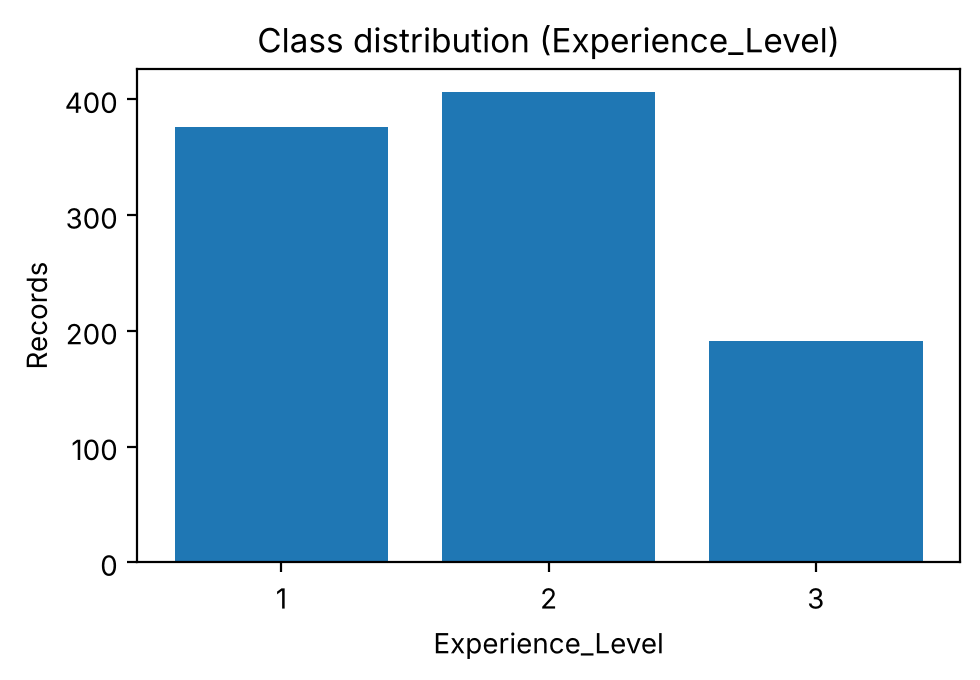

,count,mean,std,min,25%,50%,75%,max
Age,973.0,38.683,12.181,18.00,28.00,40.00,49.00,59.00
Weight (kg),973.0,73.855,21.208,40.00,58.10,70.00,86.00,129.90
Height (m),973.0,1.723,0.128,1.50,1.62,1.71,1.80,2.00
Max_BPM,973.0,179.884,11.526,160.00,170.00,180.00,190.00,199.00
Avg_BPM,973.0,143.767,14.345,120.00,131.00,143.00,156.00,169.00
Resting_BPM,973.0,62.223,7.327,50.00,56.00,62.00,68.00,74.00
Session_Duration (hours),973.0,1.256,0.343,0.50,1.04,1.26,1.46,2.00
Calories_Burned,973.0,905.422,272.642,303.00,720.00,893.00,1076.00,1783.00
Fat_Percentage,973.0,24.977,6.259,10.00,21.30,26.20,29.30,35.00
Water_Intake (liters),973.0,2.627,0.600,1.50,2.20,2.60,3.10,3.70


In [3]:
counts = df[TARGET_COL].value_counts().sort_index()
print(counts)
plt.figure(figsize=(5, 3.5))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Class distribution (Experience_Level)"); plt.xlabel("Experience_Level"); plt.ylabel("Records")
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=200); plt.show()

num_df = df.select_dtypes(include=[np.number])
num_df.describe().T.round(3)

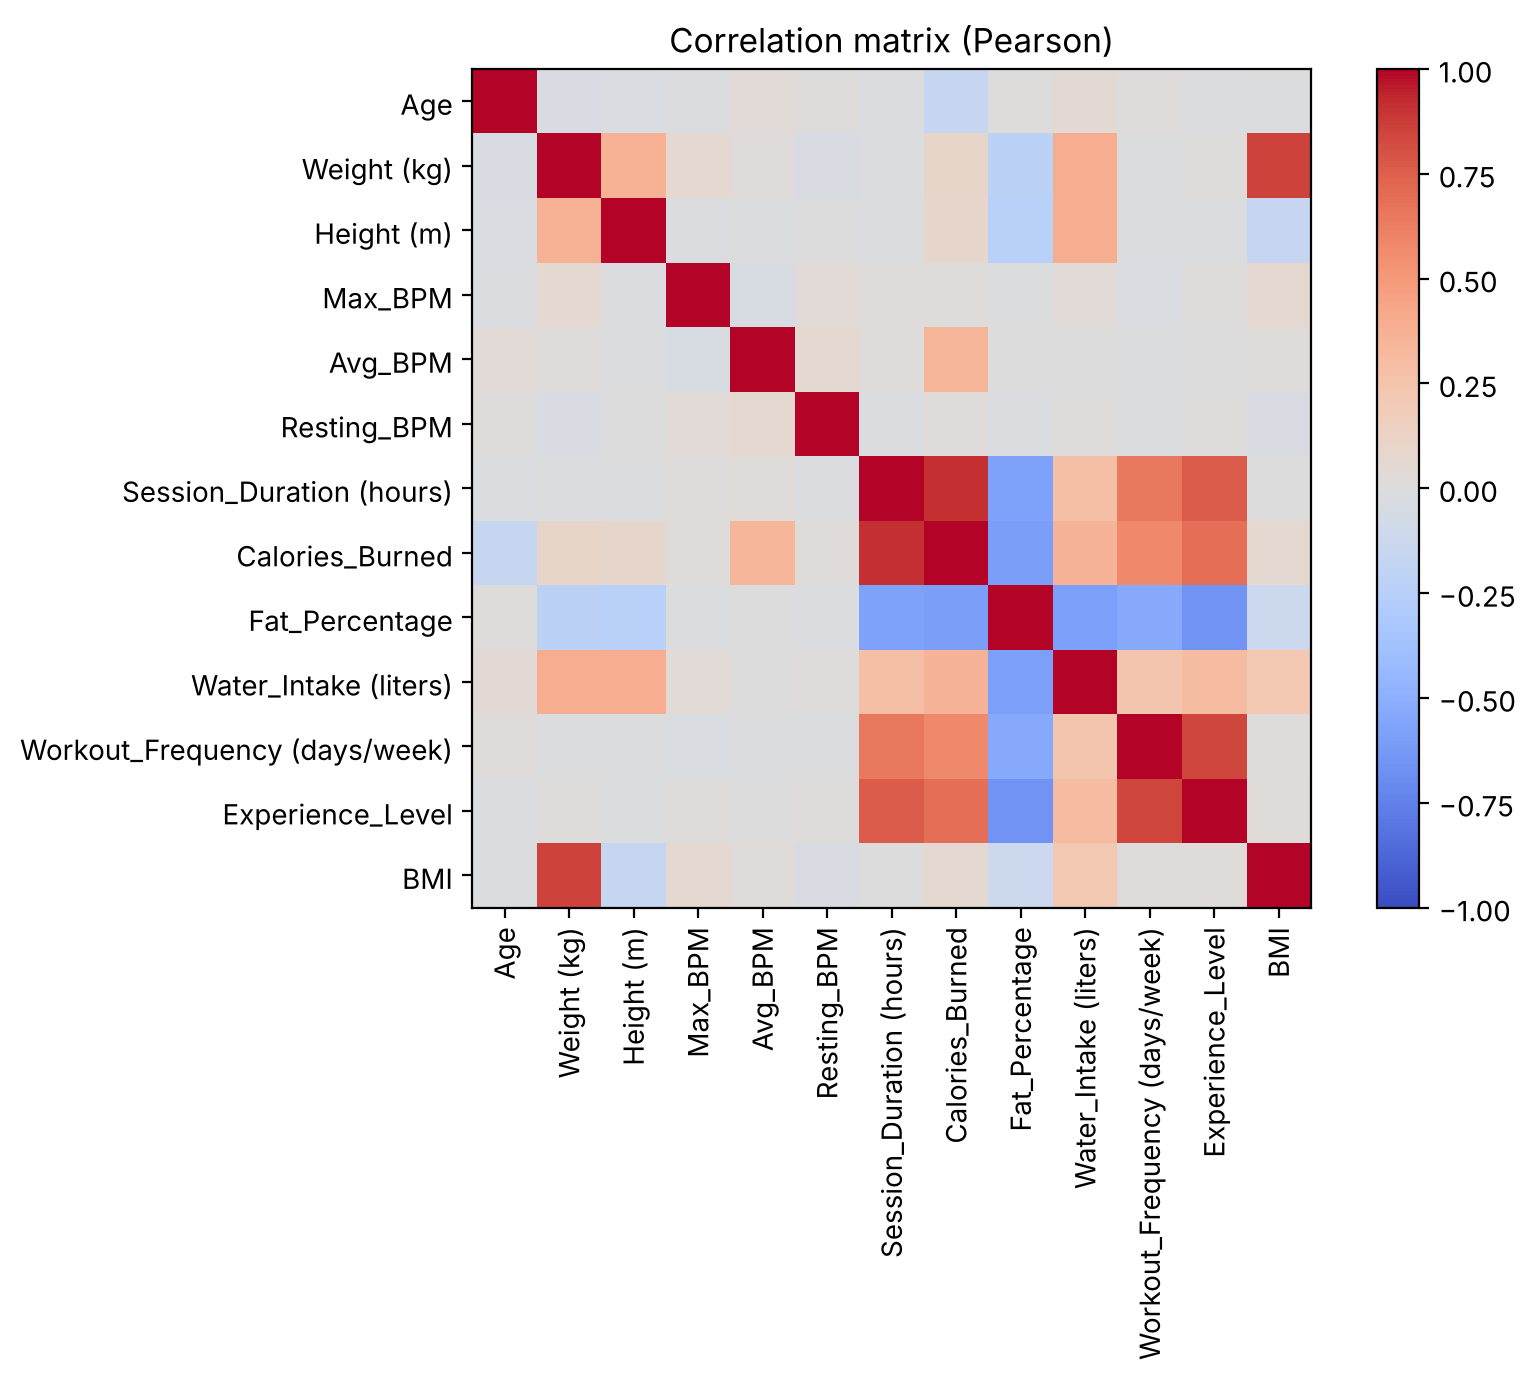

,feature_1,feature_2,r,abs_r
85,Session_Duration (hours),Calories_Burned,0.908,0.908
25,Weight (kg),BMI,0.853,0.853
141,Workout_Frequency (days/week),Experience_Level,0.837,0.837
89,Session_Duration (hours),Experience_Level,0.765,0.765
102,Calories_Burned,Experience_Level,0.694,0.694
115,Fat_Percentage,Experience_Level,-0.654,0.654
88,Session_Duration (hours),Workout_Frequency (days/week),0.644,0.644
99,Calories_Burned,Fat_Percentage,-0.598,0.598
113,Fat_Percentage,Water_Intake (liters),-0.589,0.589
86,Session_Duration (hours),Fat_Percentage,-0.582,0.582


Correlation of each feature with the target:


Workout_Frequency (days/week)    0.837
Session_Duration (hours)         0.765
Calories_Burned                  0.694
Water_Intake (liters)            0.304
BMI                              0.016
Weight (kg)                      0.003
Resting_BPM                      0.002
Max_BPM                          0.001
Avg_BPM                         -0.001
Height (m)                      -0.010
Age                             -0.019
Fat_Percentage                  -0.654
Name: Experience_Level, dtype: float64

In [4]:
# Pearson correlations: heat-map + the 10 strongest pairs
corr = num_df.corr(method="pearson")
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90); plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar(); plt.title("Correlation matrix (Pearson)"); plt.tight_layout()
plt.savefig("figures/correlation_heatmap_pearson.png", dpi=200); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
display(pairs.sort_values("abs_r", ascending=False).head(10).round(3))

print("Correlation of each feature with the target:")
corr[TARGET_COL].drop(TARGET_COL).sort_values(ascending=False).round(3)

Weight (kg)                      0.772
BMI                              0.764
Height (m)                       0.339
Experience_Level                 0.319
Calories_Burned                  0.278
Workout_Frequency (days/week)    0.150
Avg_BPM                          0.086
Water_Intake (liters)            0.071
Session_Duration (hours)         0.026
Max_BPM                         -0.038
Resting_BPM                     -0.072
Age                             -0.078
Fat_Percentage                  -0.635
dtype: float64


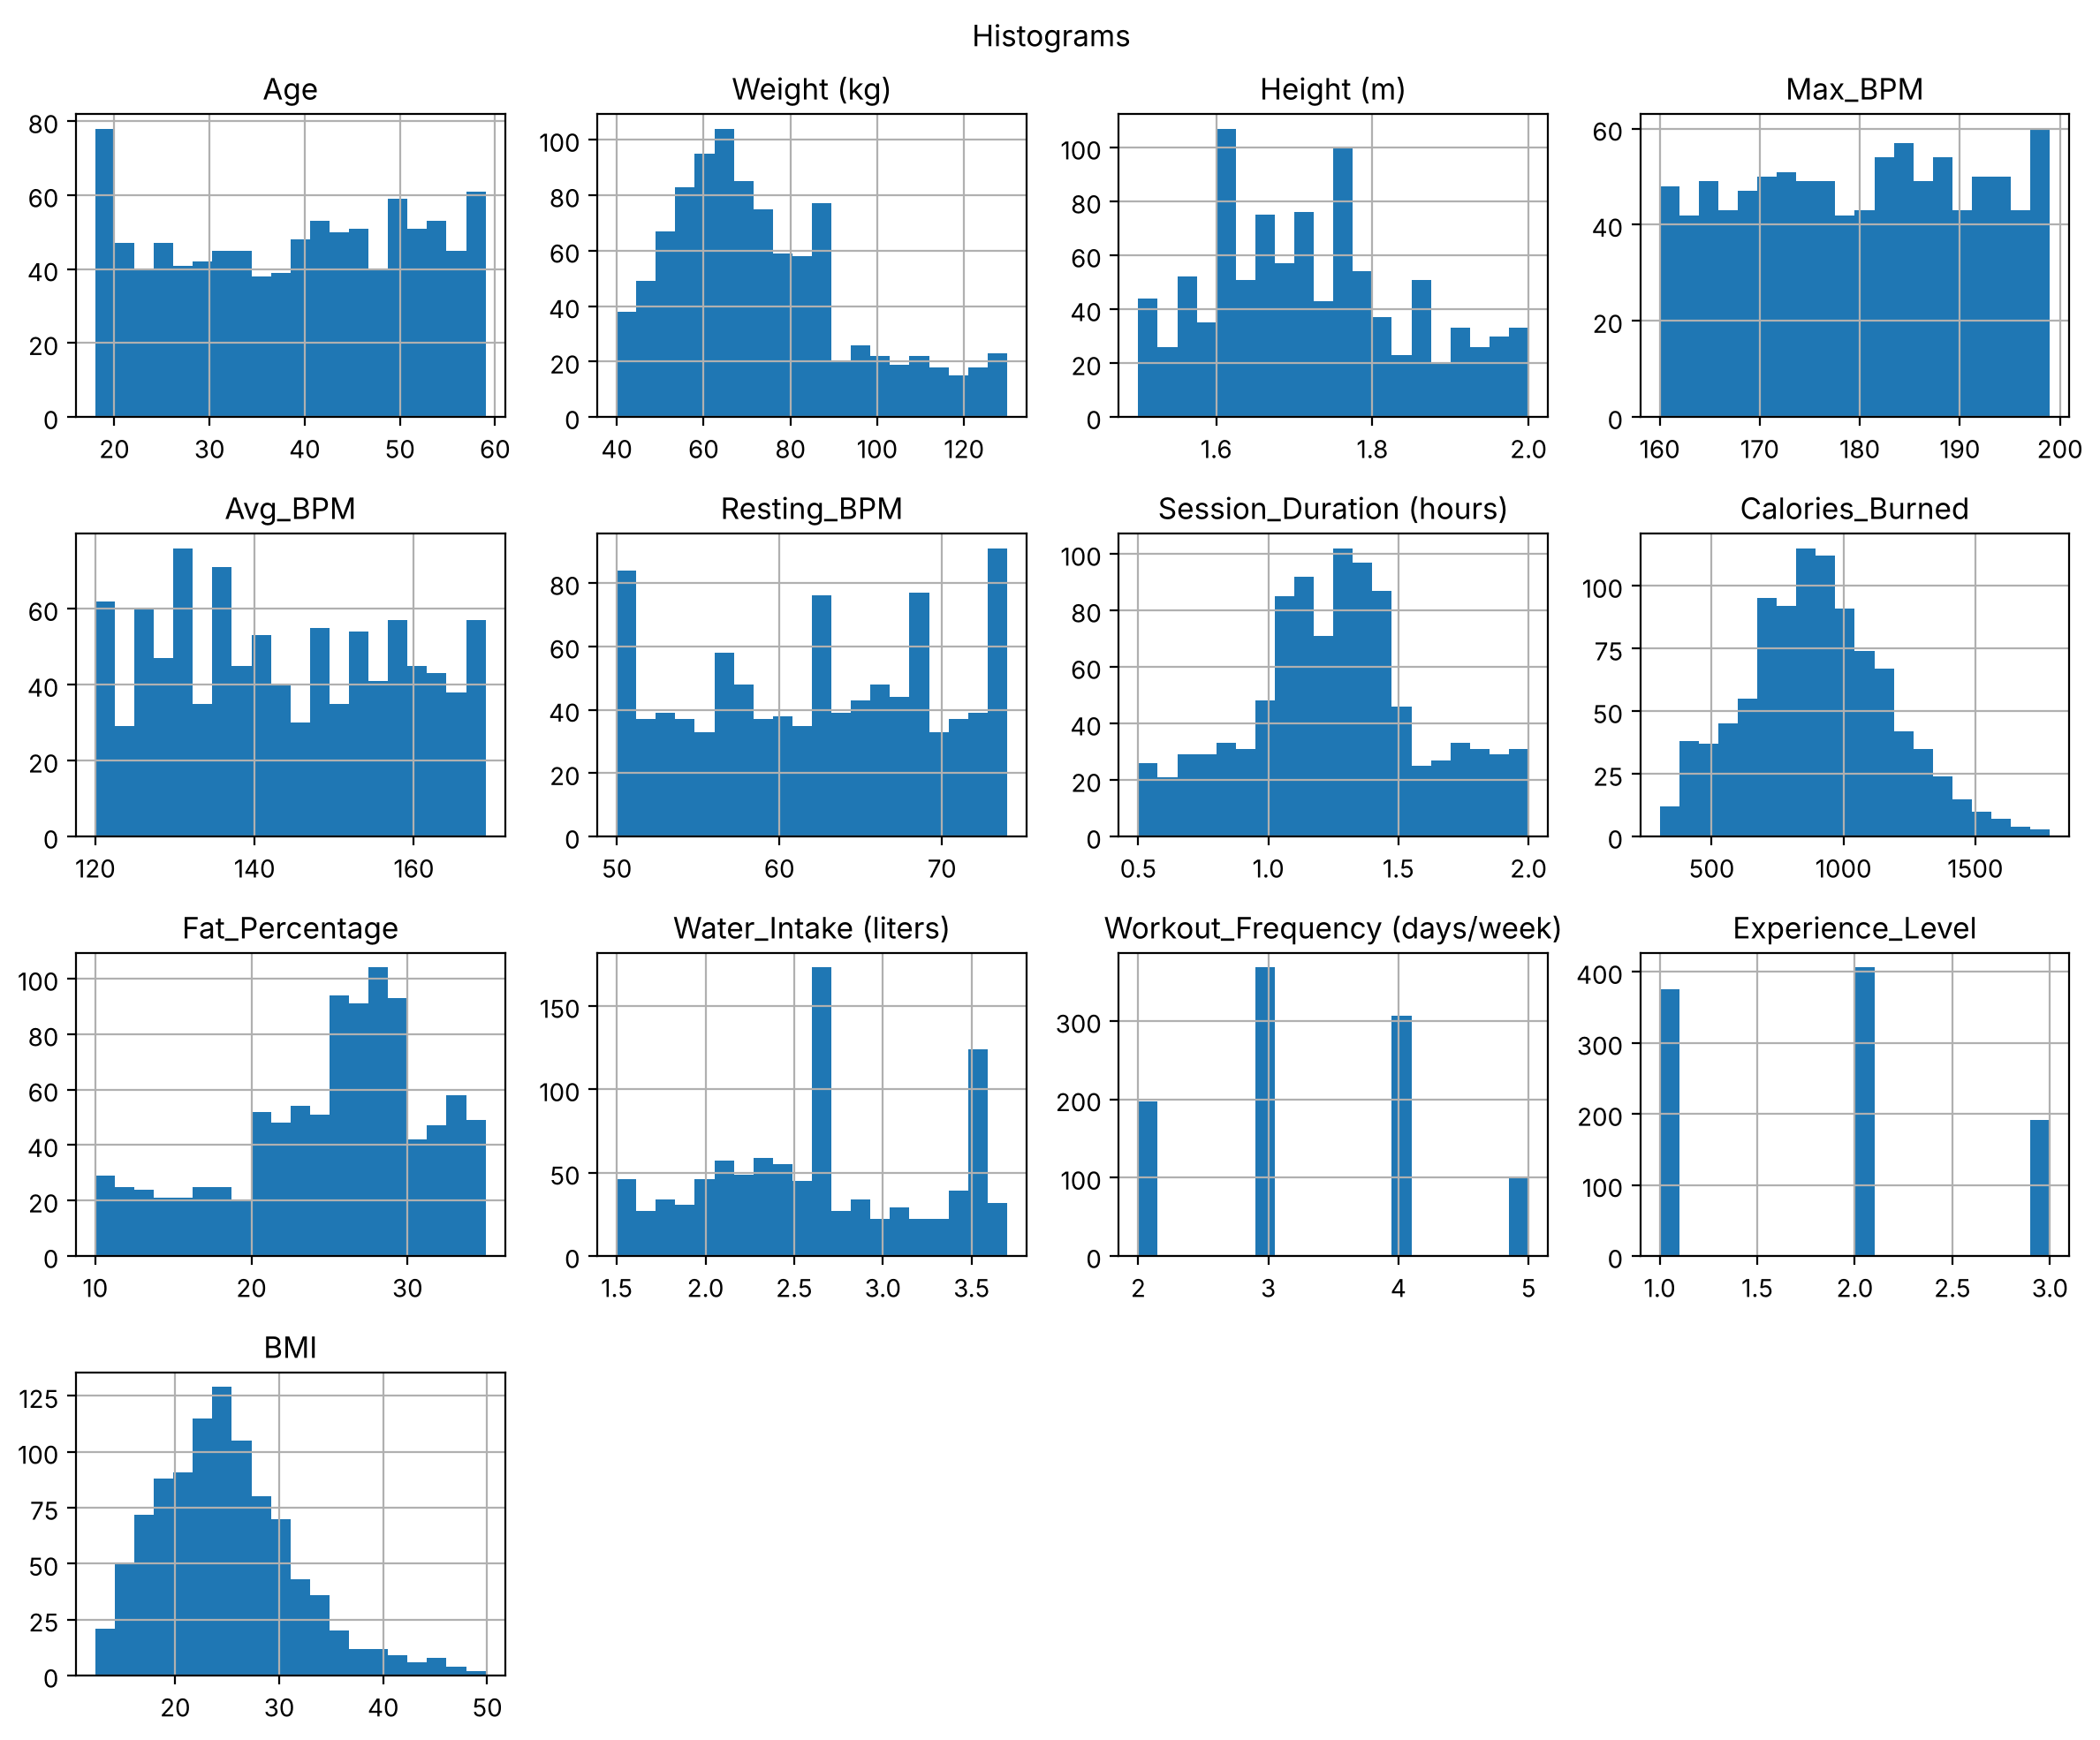

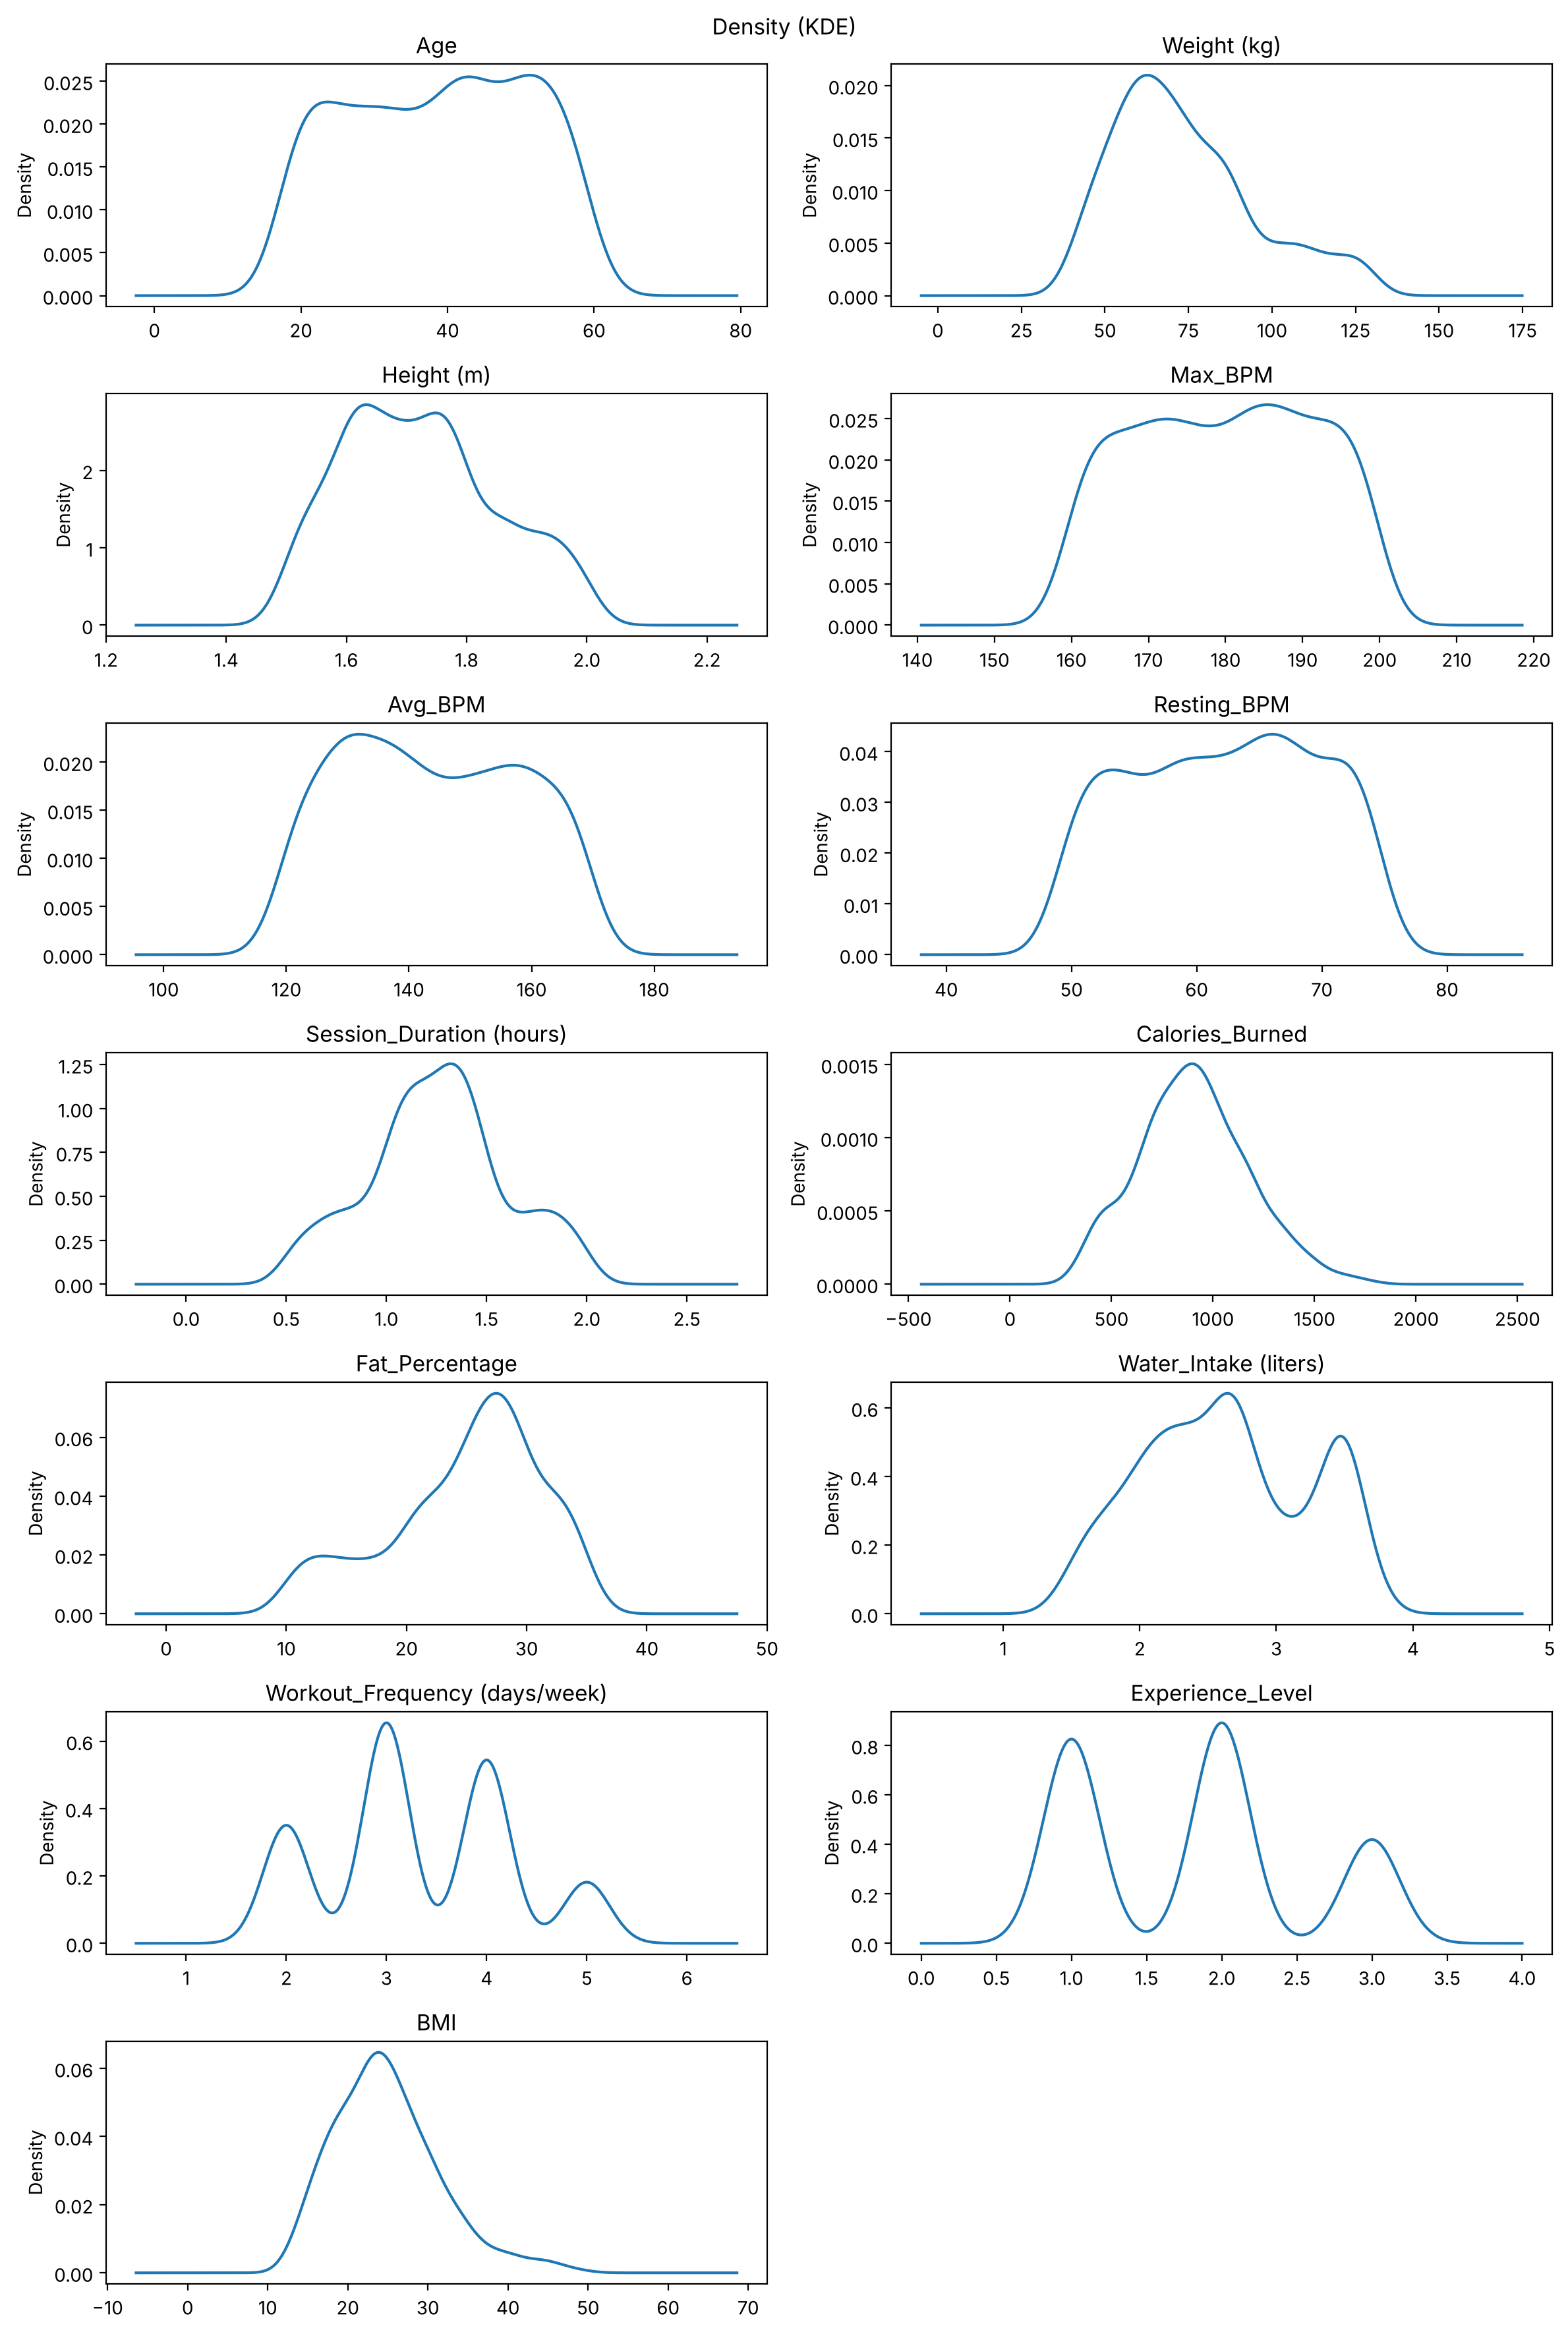

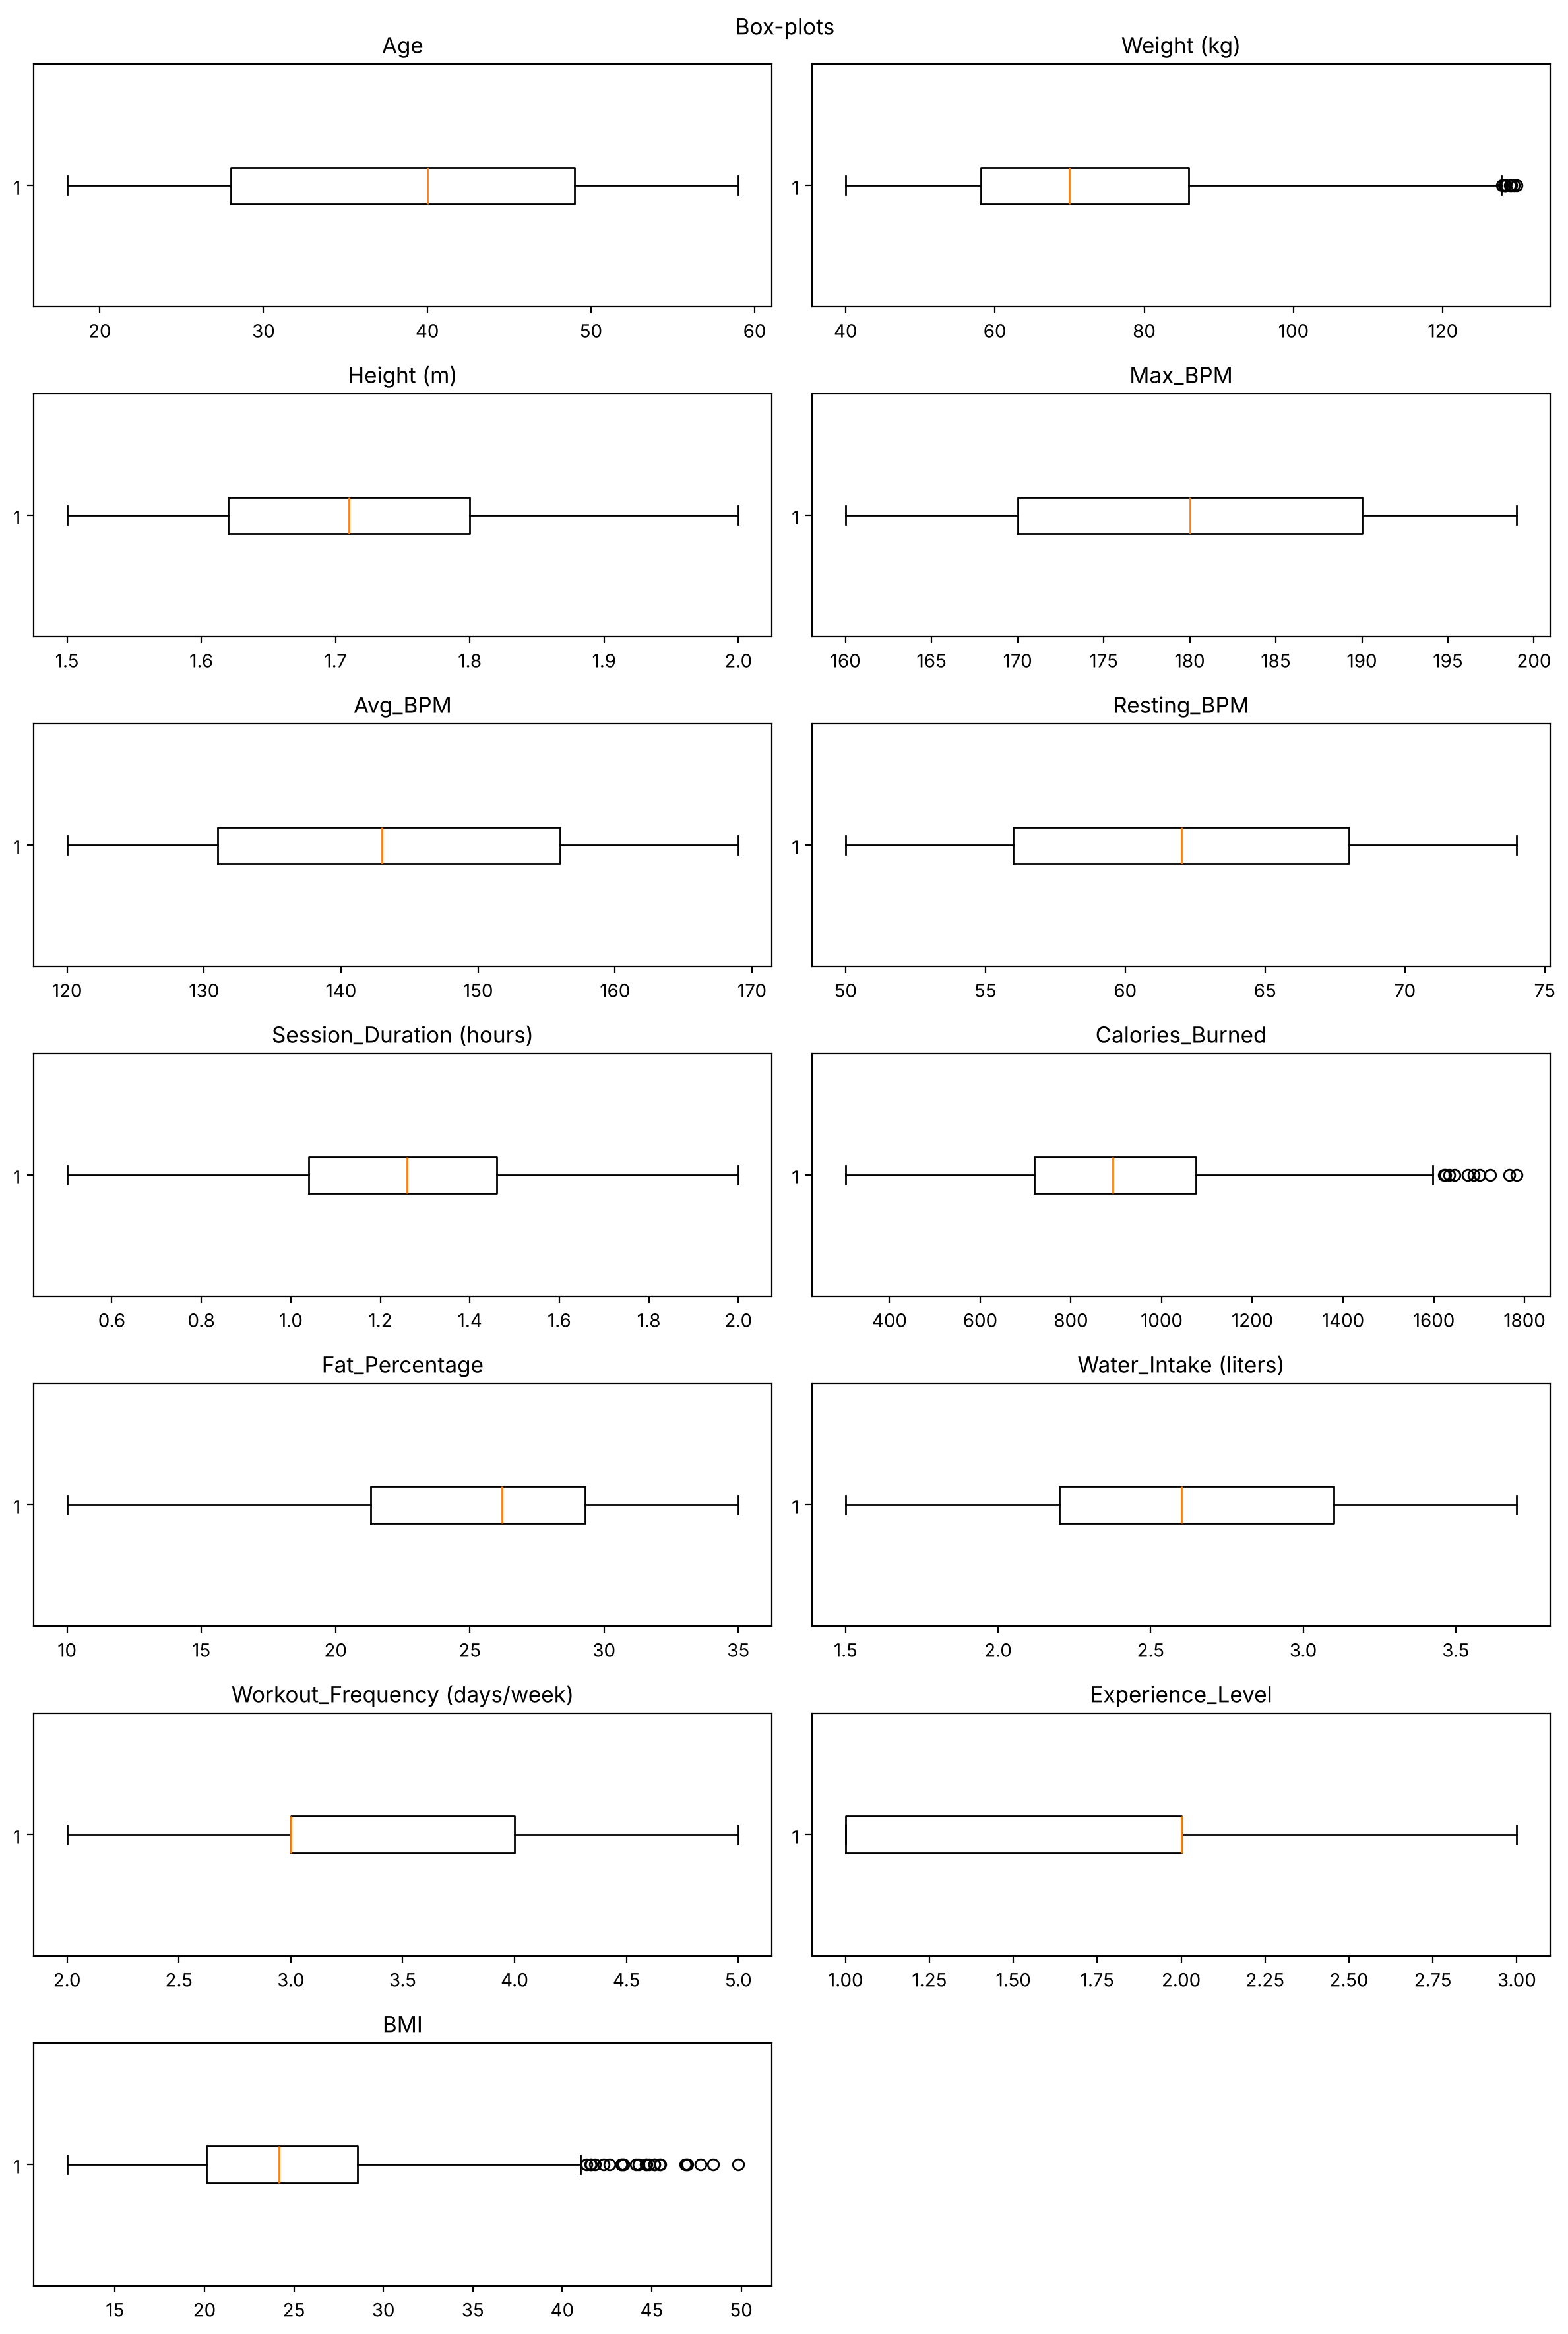

In [5]:
# Skewness, histograms, KDE and box-plots of the numeric attributes
print(num_df.skew().sort_values(ascending=False).round(3))

num_df.hist(bins=20, figsize=(12, 10)); plt.suptitle("Histograms"); plt.tight_layout()
plt.savefig("figures/histograms_grid.png", dpi=200); plt.show()

fig, axes = plt.subplots(7, 2, figsize=(12, 18))
for ax, c in zip(axes.ravel(), num_df.columns):
    num_df[c].plot(kind="kde", ax=ax, title=c)
for ax in axes.ravel()[len(num_df.columns):]:
    ax.axis("off")
plt.suptitle("Density (KDE)"); plt.tight_layout(); plt.savefig("figures/kde_grid.png", dpi=200); plt.show()

fig, axes = plt.subplots(7, 2, figsize=(12, 18))
for ax, c in zip(axes.ravel(), num_df.columns):
    ax.boxplot(num_df[c].dropna(), vert=False); ax.set_title(c)
for ax in axes.ravel()[len(num_df.columns):]:
    ax.axis("off")
plt.suptitle("Box-plots"); plt.tight_layout(); plt.savefig("figures/boxplots_grid.png", dpi=200); plt.show()

**What the EDA already tells us.** `Workout_Frequency` (r = 0.84), `Session_Duration` (0.77) and `Calories_Burned` (0.69) correlate strongly with the target, `Fat_Percentage` correlates negatively (-0.65), while age, heart rate, height and weight have practically zero correlation. `Calories_Burned` is itself almost a function of `Session_Duration` (r = 0.91), so it carries little extra information.

## 3. Train/test split and preprocessing
75 % / 25 % stratified split. Preprocessing lives inside a `Pipeline`, so scaling and encoding are learned from the training folds only (no data leakage, also inside cross-validation). Scaling matters for KNN (distance-based) but not for trees.

In [6]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]   # Gender, Workout_Type
print("Numeric:", num_cols); print("Categorical:", cat_cols)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
labels = sorted(y.unique())

Train: (729, 14) | Test: (244, 14)
Numeric: ['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Calories_Burned', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)', 'BMI']
Categorical: ['Gender', 'Workout_Type']


## 4. Baseline models (default settings)

In [7]:
def evaluate_model(name, model):
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print("=" * 60); print(name)
    print(f"10-fold CV accuracy: mean={cv_scores.mean():.3f}, std={cv_scores.std():.3f} | test accuracy: {acc:.3f}")
    print(classification_report(y_test, y_pred, digits=3))
    return {"model": name, "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(), "test_acc": acc}

baseline = [
    evaluate_model("KNN (k=7)", Pipeline([("pre", preprocess), ("m", KNeighborsClassifier(n_neighbors=7))])),
    evaluate_model("Decision Tree (default, unrestricted)", Pipeline([("pre", preprocess), ("m", DecisionTreeClassifier(random_state=SEED))])),
]
pd.DataFrame(baseline).round(3)

KNN (k=7)
10-fold CV accuracy: mean=0.833, std=0.050 | test accuracy: 0.852
              precision    recall  f1-score   support

           1      0.815     0.798     0.806        94
           2      0.817     0.833     0.825       102
           3      1.000     1.000     1.000        48

    accuracy                          0.852       244
   macro avg      0.878     0.877     0.877       244
weighted avg      0.852     0.852     0.852       244



Decision Tree (default, unrestricted)
10-fold CV accuracy: mean=0.851, std=0.045 | test accuracy: 0.828
              precision    recall  f1-score   support

           1      0.750     0.830     0.788        94
           2      0.826     0.745     0.784       102
           3      1.000     1.000     1.000        48

    accuracy                          0.828       244
   macro avg      0.859     0.858     0.857       244
weighted avg      0.831     0.828     0.828       244



,model,cv_mean,cv_std,test_acc
0,KNN (k=7),0.833,0.050,0.852
1,"Decision Tree (default, unrestricted)",0.851,0.045,0.828


## 5. Hyper-parameter tuning
Both models are tuned with `GridSearchCV` (10-fold stratified CV) **on the training set only**; the test set is touched once at the end.
The unrestricted tree (depth 17, 60 leaves) memorises noise. Limiting its depth is the single most important improvement.

In [8]:
knn_grid = GridSearchCV(
    Pipeline([("pre", preprocess), ("m", KNeighborsClassifier())]),
    {"m__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "m__weights": ["uniform", "distance"]},
    cv=cv, scoring="accuracy").fit(X_train, y_train)

dt_grid = GridSearchCV(
    Pipeline([("pre", preprocess), ("m", DecisionTreeClassifier(random_state=SEED))]),
    {"m__max_depth": [2, 3, 4, 5, 6, 8, None], "m__min_samples_leaf": [1, 5, 10, 20], "m__criterion": ["gini", "entropy"]},
    cv=cv, scoring="accuracy").fit(X_train, y_train)

for name, g in [("KNN", knn_grid), ("Decision Tree", dt_grid)]:
    i = g.best_index_
    print(f"{name}: best params = {g.best_params_}\n   CV accuracy = {g.best_score_:.3f} ± {g.cv_results_['std_test_score'][i]:.3f}")

res = pd.DataFrame(knn_grid.cv_results_)[["param_m__n_neighbors", "param_m__weights", "mean_test_score", "std_test_score"]]
res.sort_values("mean_test_score", ascending=False).head(6).round(4)

KNN: best params = {'m__n_neighbors': 21, 'm__weights': 'distance'}
   CV accuracy = 0.859 ± 0.036
Decision Tree: best params = {'m__criterion': 'gini', 'm__max_depth': 4, 'm__min_samples_leaf': 1}
   CV accuracy = 0.896 ± 0.036


,param_m__n_neighbors,param_m__weights,mean_test_score,std_test_score
13,21,distance,0.8588,0.0356
12,21,uniform,0.8560,0.0373
8,11,uniform,0.8451,0.0440
9,11,distance,0.8451,0.0461
10,15,uniform,0.8450,0.0306
11,15,distance,0.8436,0.0287


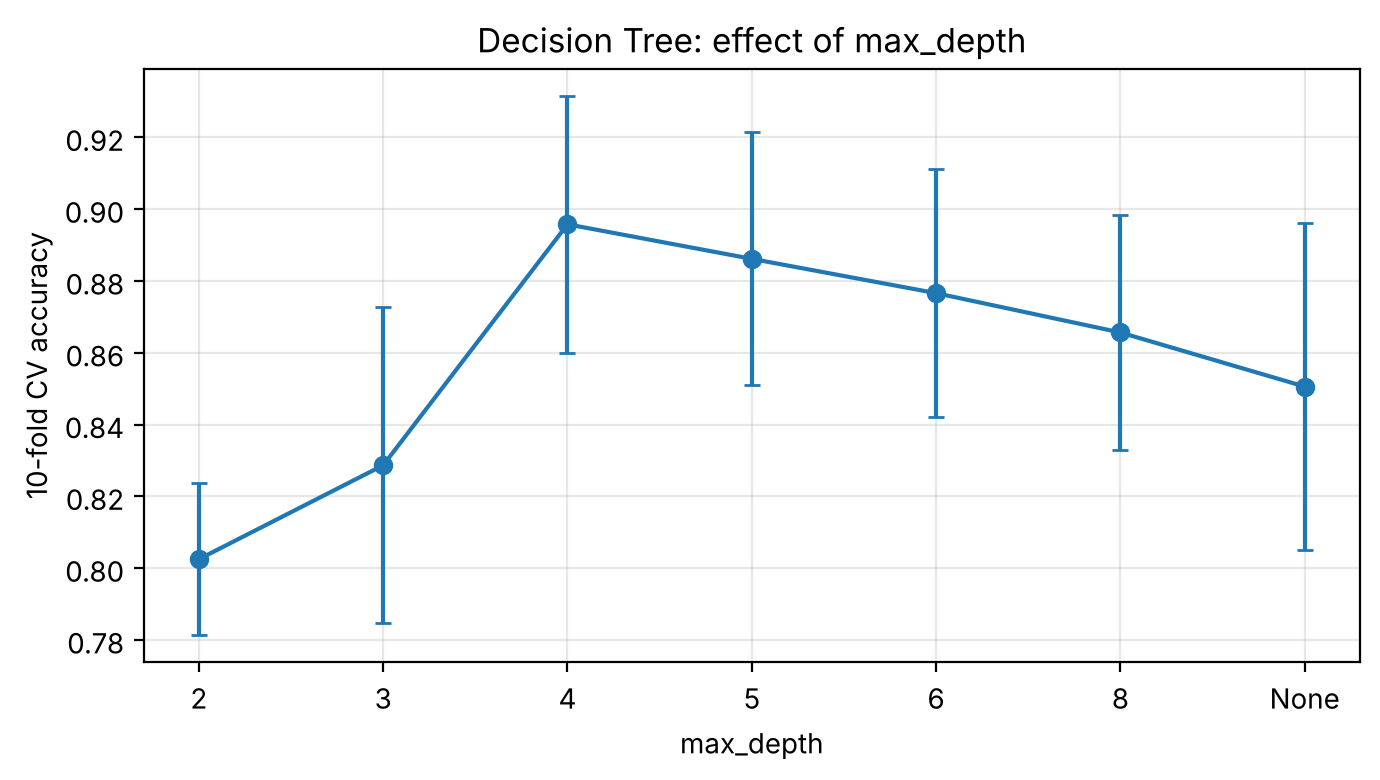

,mean_test_score,std_test_score
depth,,
2,0.8025,0.0212
3,0.8287,0.0441
4,0.8958,0.0358
5,0.8861,0.0352
6,0.8766,0.0345
8,0.8656,0.0327
None,0.8506,0.0455


In [9]:
# Effect of tree depth (gini, min_samples_leaf=1)
d = pd.DataFrame(dt_grid.cv_results_)
d = d[(d.param_m__criterion == "gini") & (d.param_m__min_samples_leaf == 1)].copy()
d["depth"] = d.param_m__max_depth.apply(lambda v: "None" if v is None or v != v else str(int(v)))
order = [str(v) for v in [2, 3, 4, 5, 6, 8]] + ["None"]
d = d.set_index("depth").loc[order]
plt.figure(figsize=(7, 4))
plt.errorbar(d.index, d.mean_test_score, yerr=d.std_test_score, marker="o", capsize=3)
plt.xlabel("max_depth"); plt.ylabel("10-fold CV accuracy"); plt.title("Decision Tree: effect of max_depth"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/dt_depth_curve.png", dpi=200); plt.show()
d[["mean_test_score", "std_test_score"]].round(4)

## 6. Final evaluation on the held-out test set

KNN (tuned)
              precision    recall  f1-score   support

           1      0.843     0.798     0.820        94
           2      0.822     0.863     0.842       102
           3      1.000     1.000     1.000        48

    accuracy                          0.865       244
   macro avg      0.888     0.887     0.887       244
weighted avg      0.865     0.865     0.865       244

Decision Tree (tuned)
              precision    recall  f1-score   support

           1      1.000     0.798     0.888        94
           2      0.843     1.000     0.915       102
           3      1.000     1.000     1.000        48

    accuracy                          0.922       244
   macro avg      0.948     0.933     0.934       244
weighted avg      0.934     0.922     0.921       244



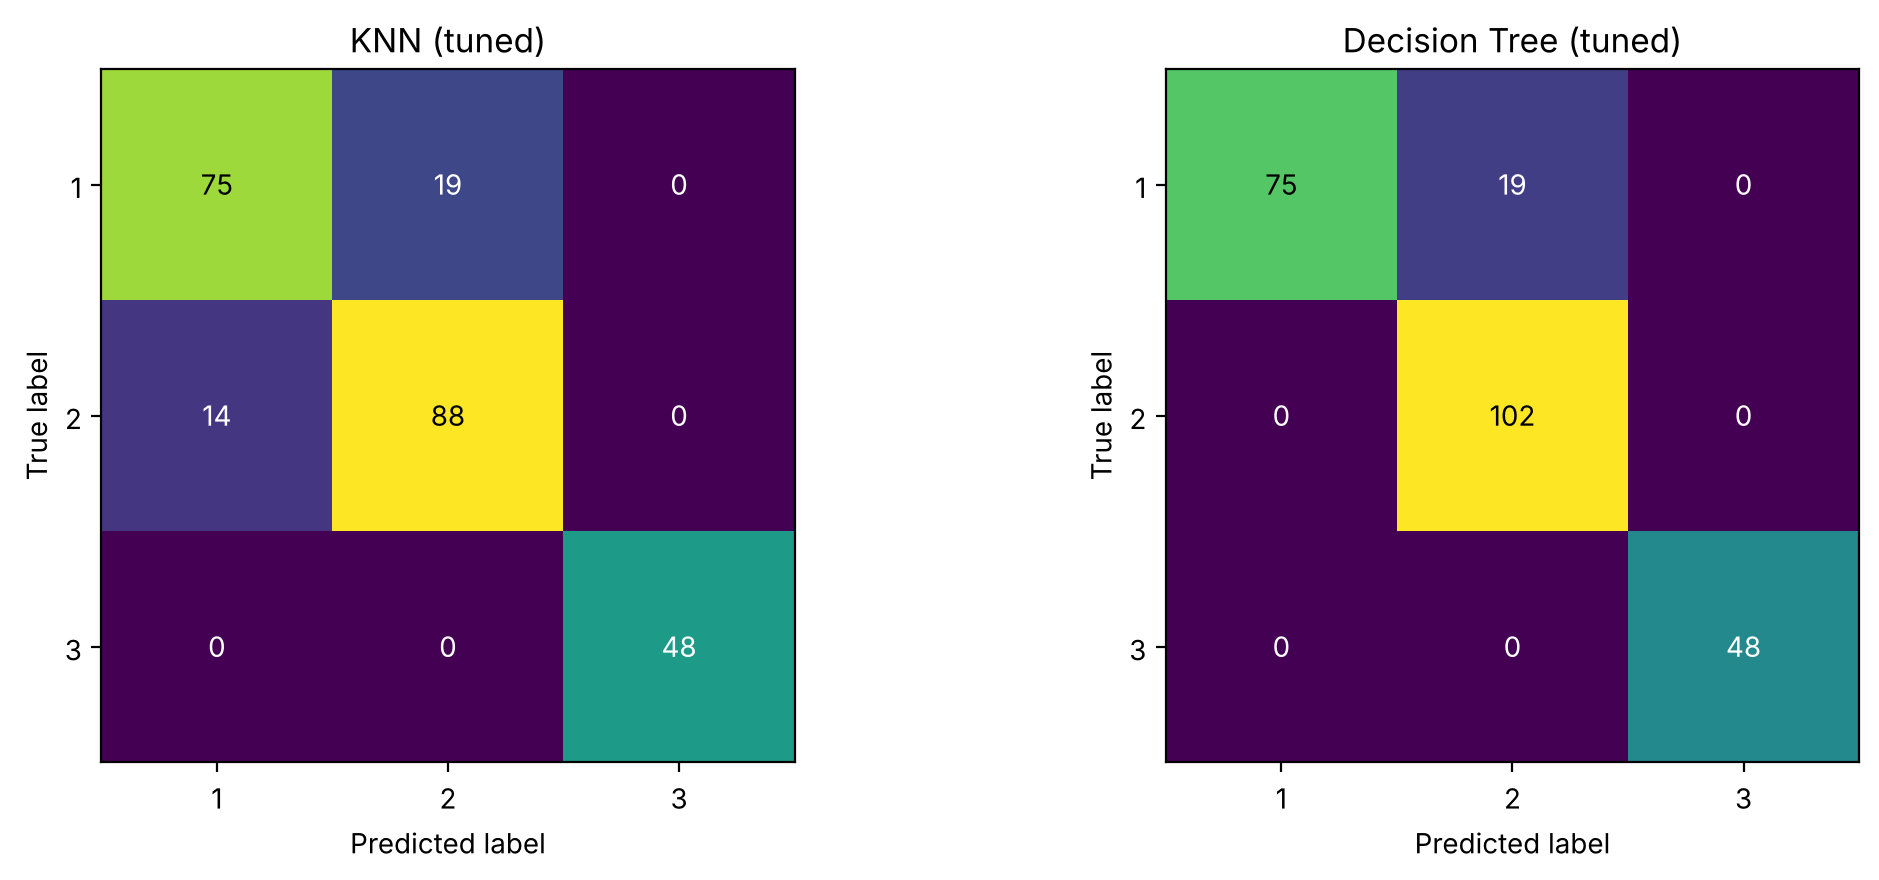

,model,cv_mean,cv_std,test_acc
0,KNN (k=7),0.833,0.050,0.852
1,"Decision Tree (default, unrestricted)",0.851,0.045,0.828
2,KNN (tuned),0.859,0.036,0.865
3,Decision Tree (tuned),0.896,0.036,0.922


In [10]:
final = {"KNN (tuned)": knn_grid.best_estimator_, "Decision Tree (tuned)": dt_grid.best_estimator_}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, final.items()):
    y_pred = model.predict(X_test)
    print("=" * 60); print(name); print(classification_report(y_test, y_pred, digits=3))
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ax.imshow(cm); ax.set_title(name)
    ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] < 60 else "black")
    g = knn_grid if "KNN" in name else dt_grid
    rows.append({"model": name, "cv_mean": g.best_score_, "cv_std": g.cv_results_["std_test_score"][g.best_index_],
                 "test_acc": accuracy_score(y_test, y_pred)})
plt.tight_layout(); plt.savefig("figures/confusion_tuned.png", dpi=200); plt.show()
pd.DataFrame(baseline + rows).round(3)

Note on the comparison: the test set has only 244 records, so one percentage point is ~2.4 samples and the standard error of the accuracy is about ±2 pp. Differences of 1–2 pp between models (e.g. the two baselines) are **not** reliable; the jump from 0.83 to 0.92 for the regularised tree is.

## 7. What did the tree learn?

Test accuracy of the un-scaled tree: 0.922


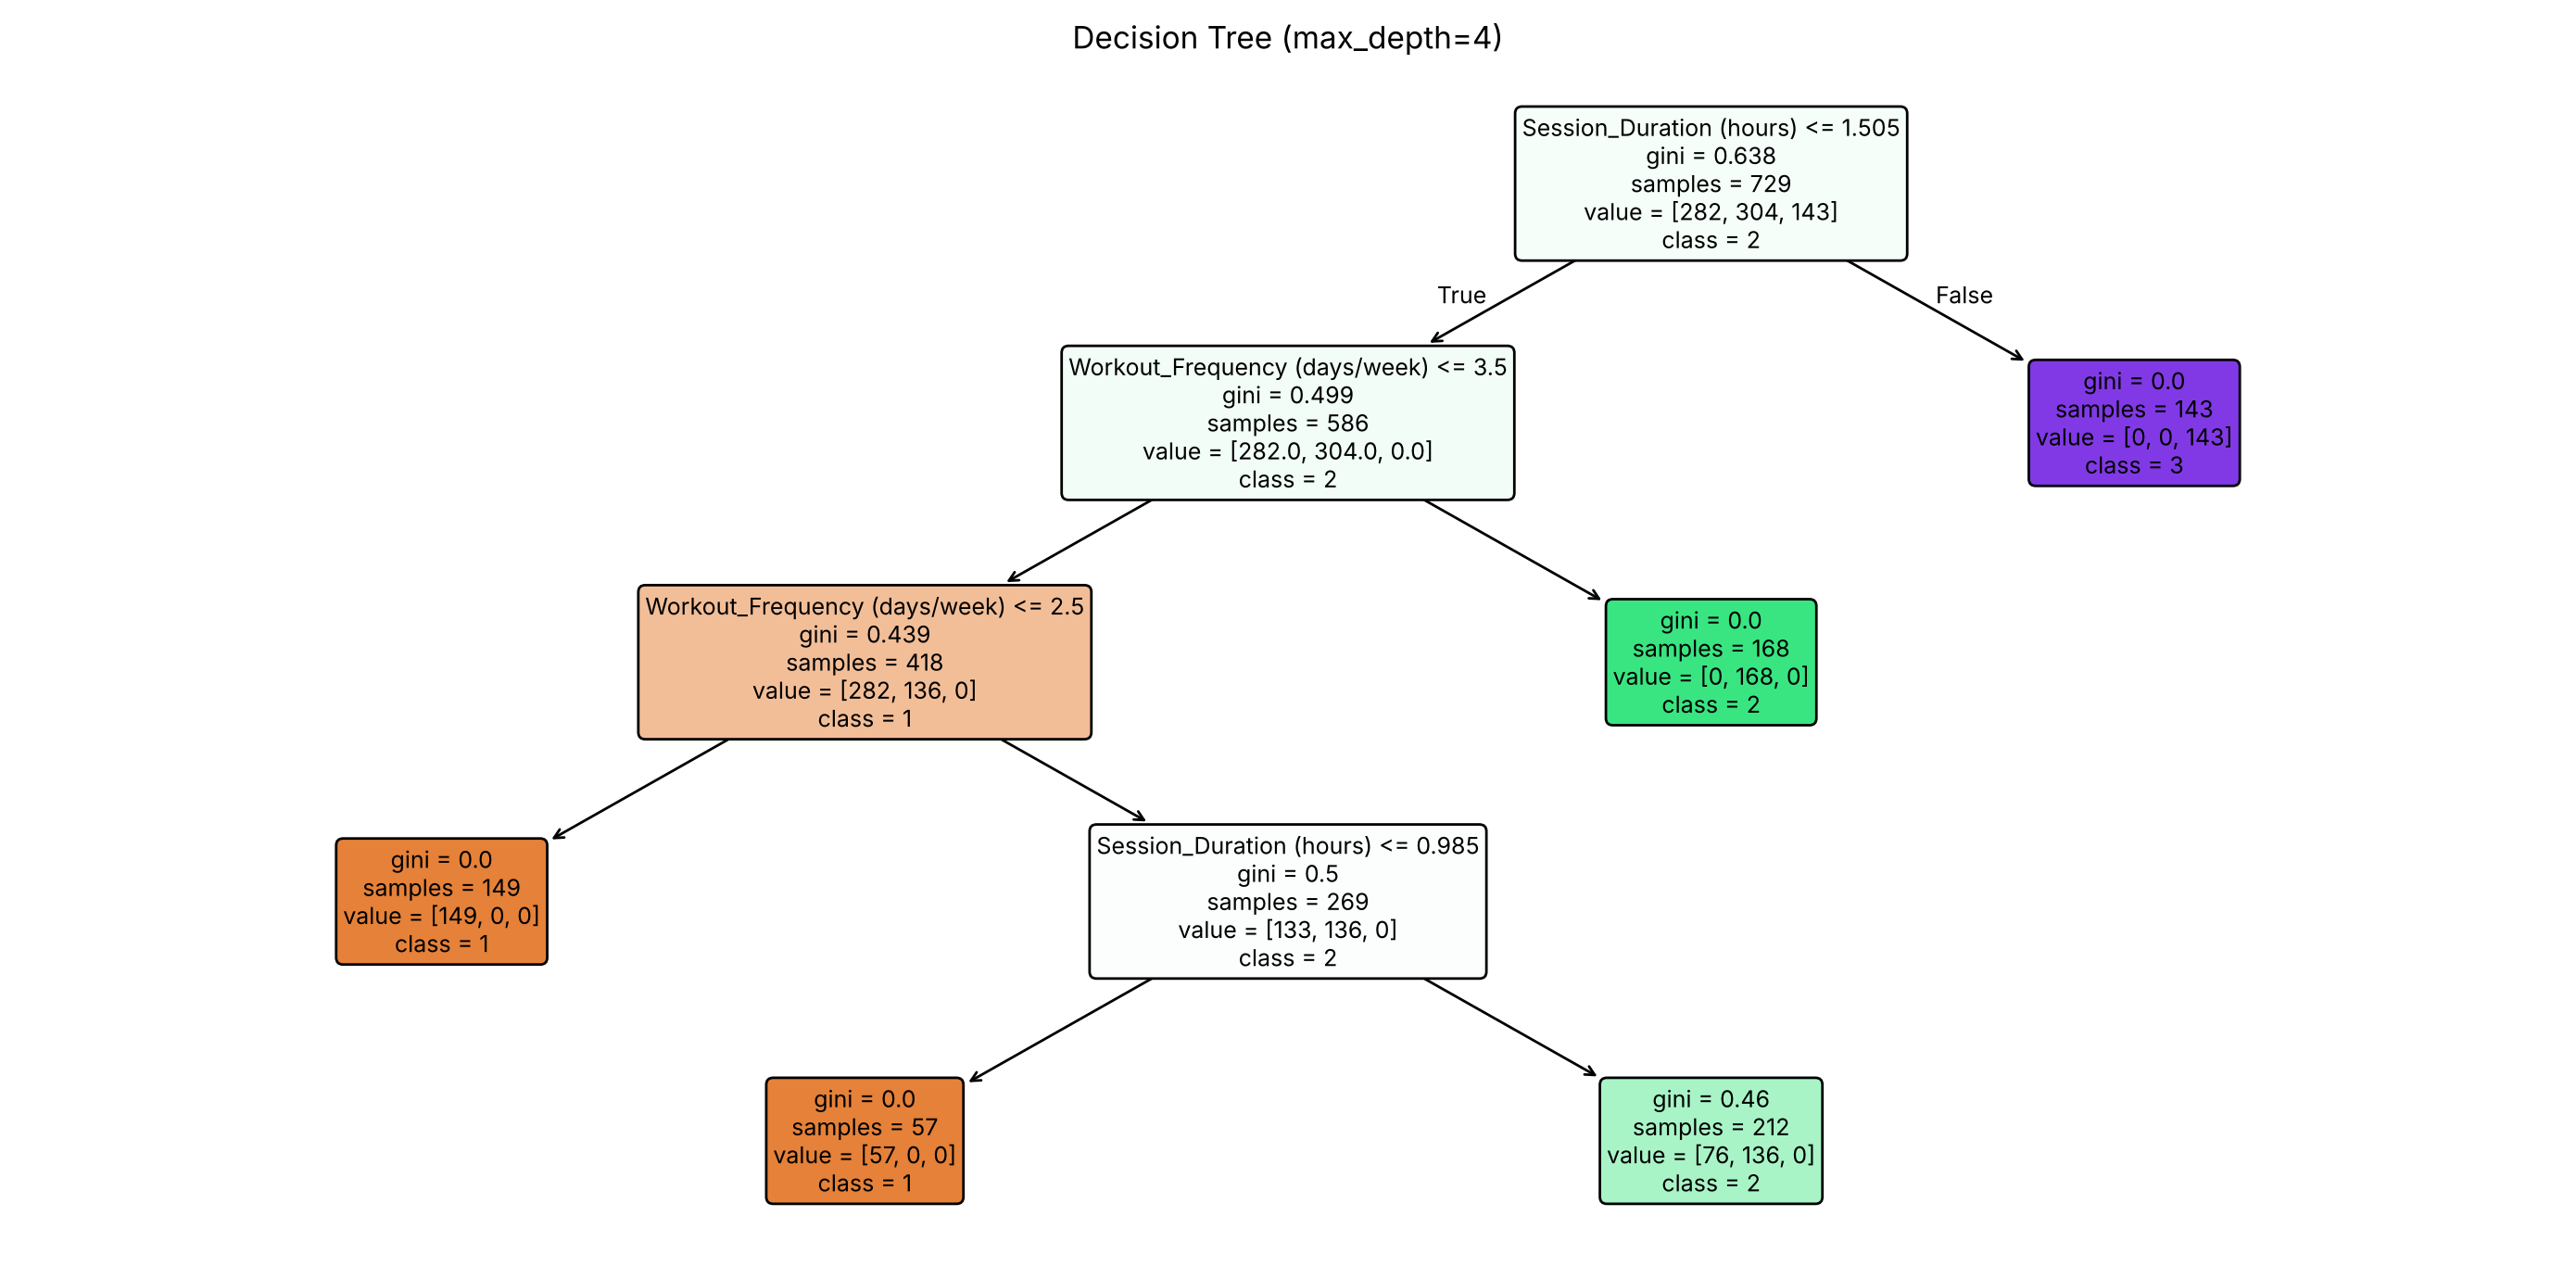

|--- Session_Duration (hours) <= 1.50
|   |--- Workout_Frequency (days/week) <= 3.50
|   |   |--- Workout_Frequency (days/week) <= 2.50
|   |   |   |--- class: 1
|   |   |--- Workout_Frequency (days/week) >  2.50
|   |   |   |--- Session_Duration (hours) <= 0.99
|   |   |   |   |--- class: 1
|   |   |   |--- Session_Duration (hours) >  0.99
|   |   |   |   |--- class: 2
|   |--- Workout_Frequency (days/week) >  3.50
|   |   |--- class: 2
|--- Session_Duration (hours) >  1.50
|   |--- class: 3



In [11]:
# Trees do not need scaling, so we refit the best tree on un-scaled features to get readable thresholds.
best = dt_grid.best_params_
X_tr_raw = pd.get_dummies(X_train, columns=cat_cols); X_te_raw = X_test.pipe(pd.get_dummies, columns=cat_cols).reindex(columns=X_tr_raw.columns, fill_value=0)
tree = DecisionTreeClassifier(max_depth=best["m__max_depth"], min_samples_leaf=best["m__min_samples_leaf"],
                              criterion=best["m__criterion"], random_state=SEED).fit(X_tr_raw, y_train)
print("Test accuracy of the un-scaled tree:", round(tree.score(X_te_raw, y_test), 3))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=list(X_tr_raw.columns), class_names=[str(l) for l in labels], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=4)"); plt.tight_layout(); plt.savefig("figures/tree_depth4.png", dpi=200); plt.show()
print(export_text(tree, feature_names=list(X_tr_raw.columns)))

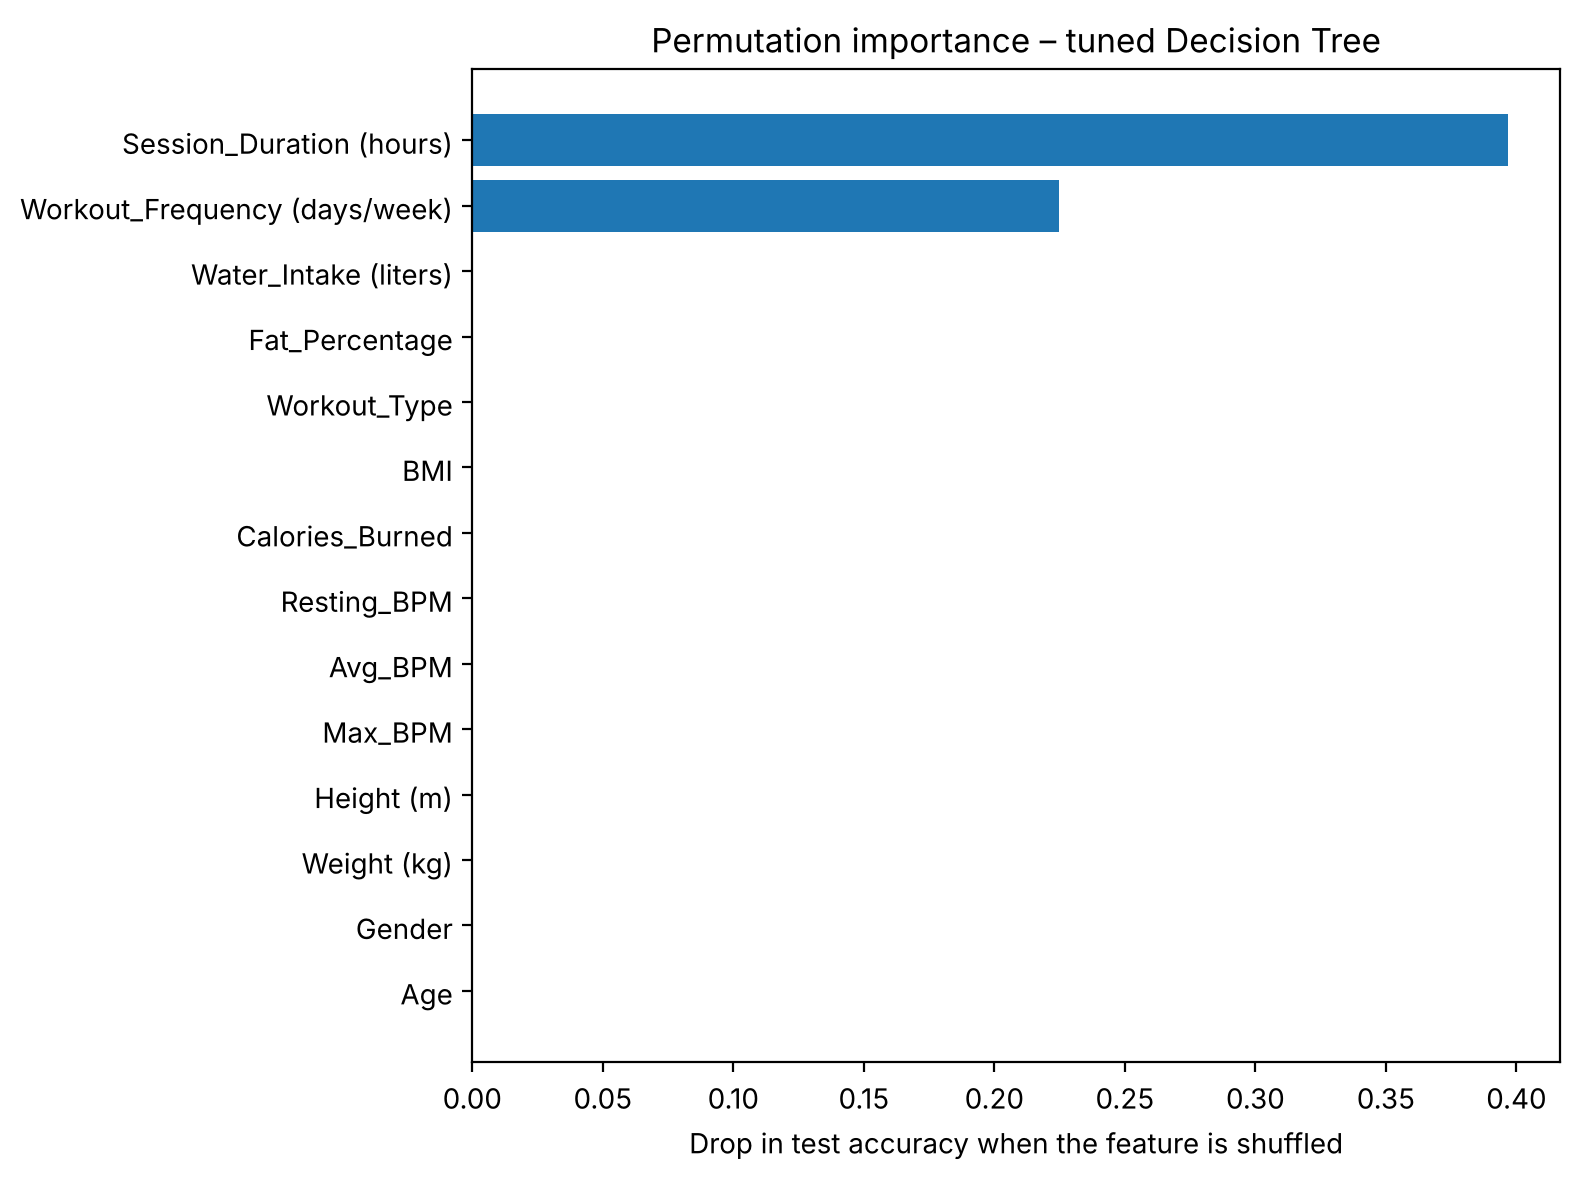

Session_Duration (hours)         0.397
Workout_Frequency (days/week)    0.225
Weight (kg)                      0.000
Height (m)                       0.000
dtype: float64

In [12]:
pi = permutation_importance(dt_grid.best_estimator_, X_test, y_test, n_repeats=30, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 6)); plt.barh(imp.index, imp.values)
plt.xlabel("Drop in test accuracy when the feature is shuffled"); plt.title("Permutation importance – tuned Decision Tree")
plt.tight_layout(); plt.savefig("figures/perm_importance_dt.png", dpi=200); plt.show()
imp.sort_values(ascending=False).head(4).round(3)

In [13]:
# Why is class 3 perfect and where do the errors come from?
print(pd.crosstab(df["Workout_Frequency (days/week)"], df[TARGET_COL]))
print()
print(df.groupby(TARGET_COL)["Session_Duration (hours)"].agg(["min", "mean", "max"]).round(2))

Experience_Level                 1    2    3
Workout_Frequency (days/week)               
2                              197    0    0
3                              179  189    0
4                                0  217   89
5                                0    0  102

                   min  mean  max
Experience_Level                 
1                 0.50  1.01  1.5
2                 1.00  1.25  1.5
3                 1.51  1.76  2.0


## 8. Conclusions
- **Best model:** Decision Tree with `max_depth=4` – CV 0.896 ± 0.036, test accuracy 0.922. Tuned KNN (k=21, distance-weighted) reaches 0.859 CV / 0.865 test. Regularisation, not the choice of algorithm, made the biggest difference.
- **The model is simple and explainable:** sessions longer than 1.5 h → class 3; otherwise training 4+ days/week → class 2, 2 days/week → class 1, and for 3 days/week the session length decides. Only `Session_Duration` and `Workout_Frequency` matter.
- **Remaining errors:** all are class 1 predicted as class 2. People who train 3×/week appear in both classes (179 vs. 189 records) with overlapping session lengths, so these two features cannot separate them.
- **Why accuracy is so high / limitations:** the dataset looks synthetic – the label is almost a deterministic function of frequency and duration, while physiological features (age, heart rate, weight) carry no signal (r ≈ 0). The model therefore shows a clean pipeline and sound methodology, but its accuracy should not be read as "heart-rate data predicts experience". On real gym data I would expect far lower accuracy.
- **Possible next steps:** Random Forest / Gradient Boosting for comparison, repeated CV or nested CV for tighter estimates, validation on a different (real) dataset.